# Exploratory Data Analysis — Credit Marketing Campaign

**Causal Marketing Uplift Platform**

This notebook explores the synthetic fintech personal-loan marketing dataset (`credit_marketing.csv`). The goal is to understand customer profiles, campaign assignment balance, and observed response patterns **before** building uplift models.

> **Reminder:** Patterns observed here describe associations in the data. They do **not** establish causal effects of marketing — that requires randomized experiments or causal inference methods.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- Plot styling ---
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
PALETTE = sns.color_palette("muted")
TREATMENT_PALETTE = {"Control": PALETTE[0], "Treatment": PALETTE[2]}
SEGMENT_ORDER = ["persuadable", "sure_thing", "lost_cause", "sleeping_dog"]
SEGMENT_LABELS = {
    "persuadable": "Persuadable",
    "sure_thing": "Sure Thing",
    "lost_cause": "Lost Cause",
    "sleeping_dog": "Sleeping Dog",
}
SEGMENT_COLORS = dict(zip(SEGMENT_ORDER, sns.color_palette("Set2", 4)))

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "figure.facecolor": "white",
})

def find_project_root() -> Path:
    """Resolve project root whether the notebook runs from / or /notebooks."""
    for candidate in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        if (candidate / "data" / "raw" / "credit_marketing.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate data/raw/credit_marketing.csv")

ROOT = find_project_root()
DATA_PATH = ROOT / "data" / "raw" / "credit_marketing.csv"
REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv(DATA_PATH)

df["group"] = df["marketing_offer"].map({0: "Control", 1: "Treatment"})
df["segment_label"] = df["customer_segment"].map(SEGMENT_LABELS)

print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 50,000  |  Columns: 19


,customer_id,customer_segment,age,gender,country,income,employment_years,account_balance,debt_ratio,credit_score,previous_loans,payment_history,credit_utilization,transaction_frequency,app_usage_frequency,marketing_offer,loan_application,group,segment_label
0,1,persuadable,55.0,Male,NL,58850.02,8.0,4149.64,0.504,656.0,2,0.612,0.665,4.0,4.0,1,0,Treatment,Persuadable
1,2,lost_cause,30.0,Female,FR,15000.00,3.0,240.35,0.739,489.0,1,0.246,0.703,1.0,1.0,1,0,Treatment,Lost Cause
2,3,lost_cause,47.0,Female,US,16197.35,5.0,1523.09,0.831,470.0,2,0.584,0.865,4.0,3.0,1,0,Treatment,Lost Cause
3,4,sleeping_dog,46.0,Male,US,36655.61,5.0,26744.45,0.141,756.0,0,0.703,0.029,3.0,0.0,1,0,Treatment,Sleeping Dog
4,5,sleeping_dog,27.0,Female,IT,78449.95,9.0,16930.00,0.043,837.0,0,0.861,0.269,4.0,0.0,0,1,Control,Sleeping Dog


## 1. Customer Demographic Analysis

Understanding who is in the campaign population: age distribution, gender mix, and geographic spread.

C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\1765384952.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_counts.values, y=country_counts.index, palette="Blues_r", ax=axes[2])


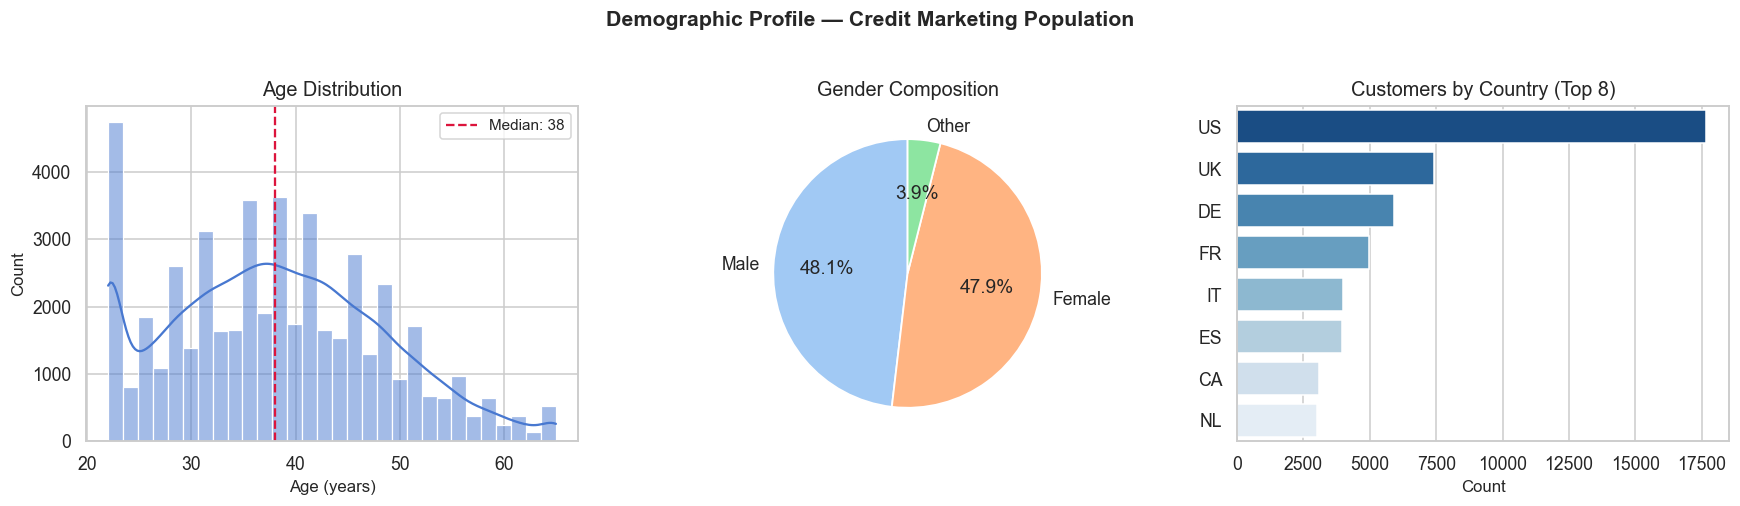

,metric,value
0,Mean age,38.2
1,Median age,38
2,Top country,US
3,Female share,47.9%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Age distribution
sns.histplot(df["age"], bins=30, kde=True, color=PALETTE[0], ax=axes[0], edgecolor="white")
axes[0].axvline(df["age"].median(), color="crimson", ls="--", lw=1.5, label=f"Median: {df['age'].median():.0f}")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Count")
axes[0].legend()

# Gender composition
gender_counts = df["gender"].value_counts()
axes[1].pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("pastel", len(gender_counts)),
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2},
)
axes[1].set_title("Gender Composition")

# Country distribution
country_counts = df["country"].value_counts().head(8)
sns.barplot(x=country_counts.values, y=country_counts.index, palette="Blues_r", ax=axes[2])
axes[2].set_title("Customers by Country (Top 8)")
axes[2].set_xlabel("Count")
axes[2].set_ylabel("")

plt.suptitle("Demographic Profile — Credit Marketing Population", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_demographics.png", bbox_inches="tight", dpi=150)
plt.show()

demo_summary = pd.DataFrame({
    "metric": ["Mean age", "Median age", "Top country", "Female share"],
    "value": [
        f"{df['age'].mean():.1f}",
        f"{df['age'].median():.0f}",
        df["country"].mode()[0],
        f"{(df['gender'] == 'Female').mean():.1%}",
    ],
})
demo_summary

## 2. Financial Feature Distributions

Income, employment tenure, account balance, and debt ratio shape creditworthiness and loan demand.

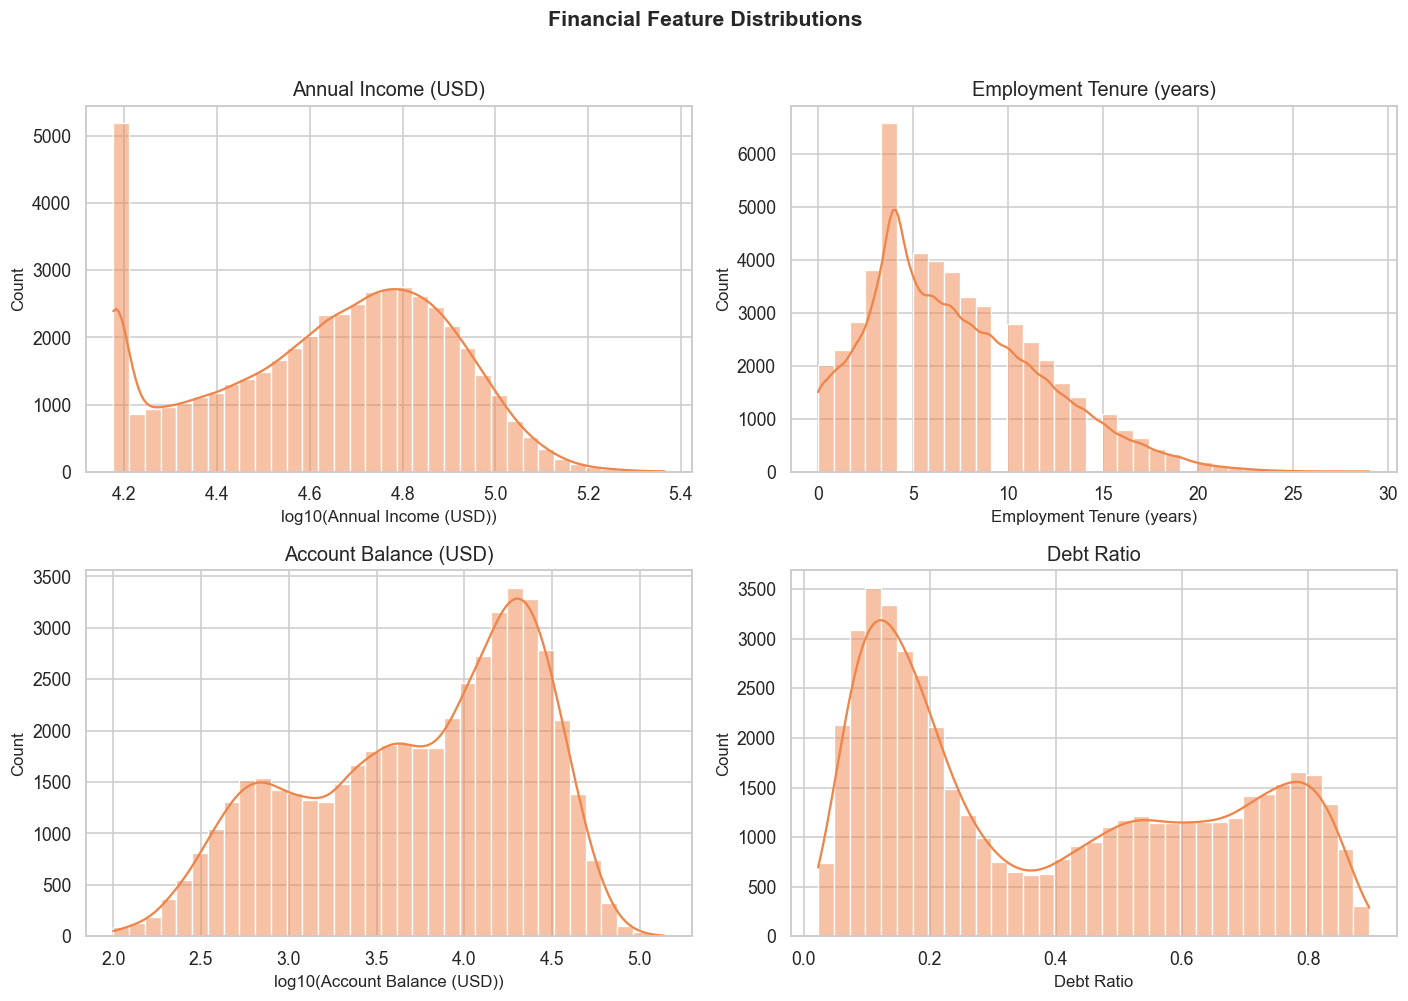

C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\2645700334.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\2645700334.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([SEGMENT_LABELS[s][:8] for s in SEGMENT_ORDER], rotation=30, ha="right")
C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\2645700334.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\2645700334.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fixe

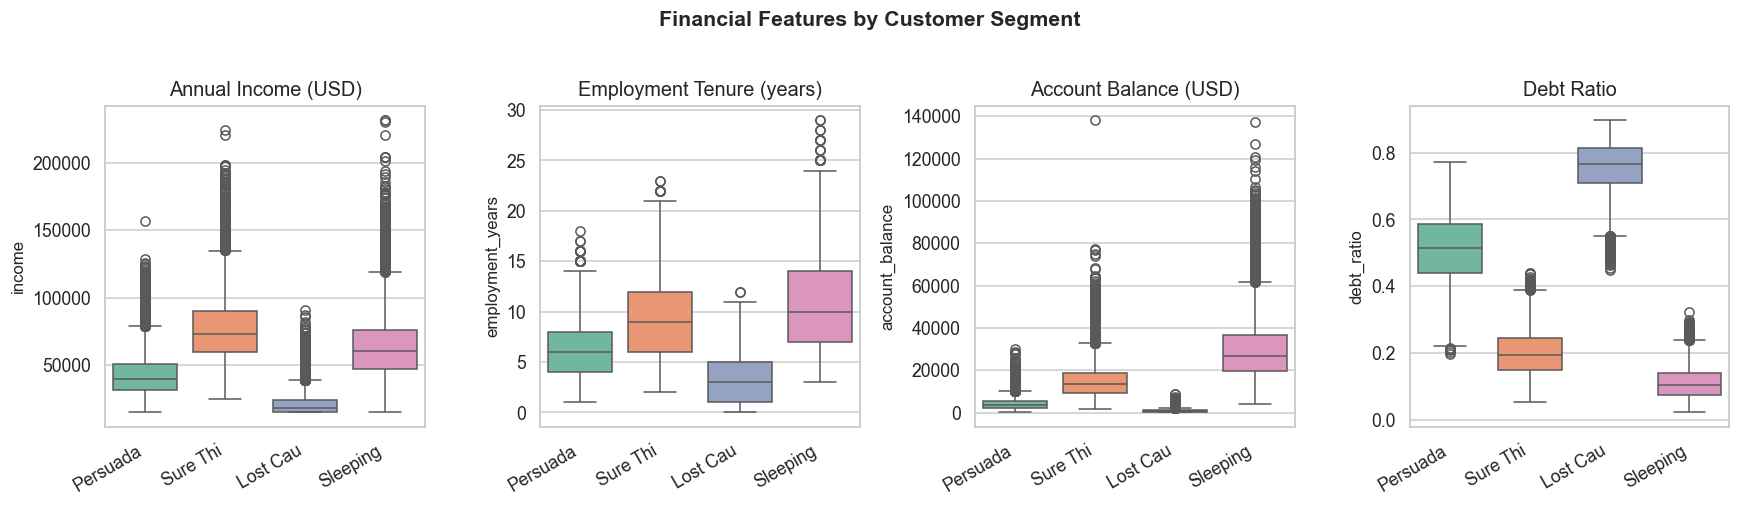

In [4]:
financial_cols = ["income", "employment_years", "account_balance", "debt_ratio"]
financial_labels = {
    "income": "Annual Income (USD)",
    "employment_years": "Employment Tenure (years)",
    "account_balance": "Account Balance (USD)",
    "debt_ratio": "Debt Ratio",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

for ax, col in zip(axes, financial_cols):
    if col in ("income", "account_balance"):
        plot_data = np.log10(df[col].clip(lower=1))
        xlabel = f"log10({financial_labels[col]})"
    else:
        plot_data = df[col]
        xlabel = financial_labels[col]
    sns.histplot(plot_data, kde=True, color=PALETTE[1], ax=ax, edgecolor="white", bins=35)
    ax.set_title(financial_labels[col])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")

plt.suptitle("Financial Feature Distributions", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_financial_distributions.png", bbox_inches="tight", dpi=150)
plt.show()

# Box plots by segment
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, financial_cols):
    sns.boxplot(
        data=df, x="customer_segment", y=col, order=SEGMENT_ORDER,
        palette=[SEGMENT_COLORS[s] for s in SEGMENT_ORDER], ax=ax,
    )
    ax.set_title(financial_labels[col])
    ax.set_xlabel("")
    ax.set_xticklabels([SEGMENT_LABELS[s][:8] for s in SEGMENT_ORDER], rotation=30, ha="right")

plt.suptitle("Financial Features by Customer Segment", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_financial_by_segment.png", bbox_inches="tight", dpi=150)
plt.show()

## 3. Credit Score Analysis

Credit score is a primary driver of loan eligibility. We examine its distribution, relationship with debt metrics, and variation across segments.

C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\1243342611.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\1243342611.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([SEGMENT_LABELS[s] for s in SEGMENT_ORDER], rotation=20, ha="right")


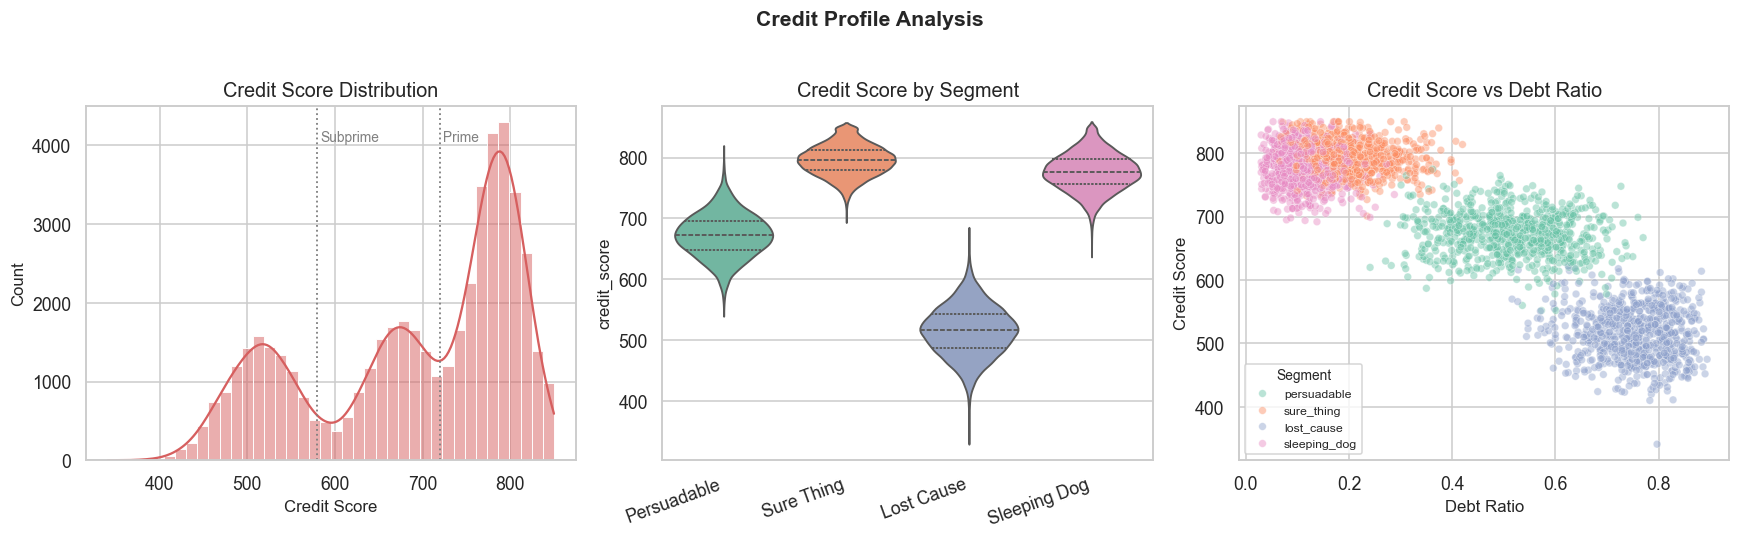

,mean,median,std
Lost Cause,515.1,516.0,40.8
Persuadable,672.4,673.0,35.7
Sleeping Dog,776.6,777.0,30.4
Sure Thing,795.9,796.0,25.3


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Overall distribution
sns.histplot(df["credit_score"], bins=40, kde=True, color=PALETTE[3], ax=axes[0], edgecolor="white")
for threshold, label in [(580, "Subprime"), (720, "Prime")]:
    axes[0].axvline(threshold, color="gray", ls=":", lw=1.2)
    axes[0].text(threshold + 3, axes[0].get_ylim()[1] * 0.9, label, fontsize=9, color="gray")
axes[0].set_title("Credit Score Distribution")
axes[0].set_xlabel("Credit Score")
axes[0].set_ylabel("Count")

# By segment
sns.violinplot(
    data=df, x="customer_segment", y="credit_score", order=SEGMENT_ORDER,
    palette=[SEGMENT_COLORS[s] for s in SEGMENT_ORDER], inner="quartile", ax=axes[1],
)
axes[1].set_title("Credit Score by Segment")
axes[1].set_xlabel("")
axes[1].set_xticklabels([SEGMENT_LABELS[s] for s in SEGMENT_ORDER], rotation=20, ha="right")

# Score vs debt ratio (association, not causation)
sample = df.sample(min(3000, len(df)), random_state=42)
sns.scatterplot(
    data=sample, x="debt_ratio", y="credit_score", hue="customer_segment",
    hue_order=SEGMENT_ORDER, palette=SEGMENT_COLORS, alpha=0.45, s=25, ax=axes[2],
)
axes[2].set_title("Credit Score vs Debt Ratio")
axes[2].set_xlabel("Debt Ratio")
axes[2].set_ylabel("Credit Score")
axes[2].legend(title="Segment", fontsize=8, title_fontsize=9)

plt.suptitle("Credit Profile Analysis", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_credit_score.png", bbox_inches="tight", dpi=150)
plt.show()

credit_summary = df.groupby("customer_segment")["credit_score"].agg(["mean", "median", "std"]).round(1)
credit_summary.index = [SEGMENT_LABELS[s] for s in credit_summary.index]
credit_summary

## 4. Treatment vs Control Comparison

Randomized campaigns should show similar covariate distributions in treatment and control groups. Large imbalances would threaten causal validity.

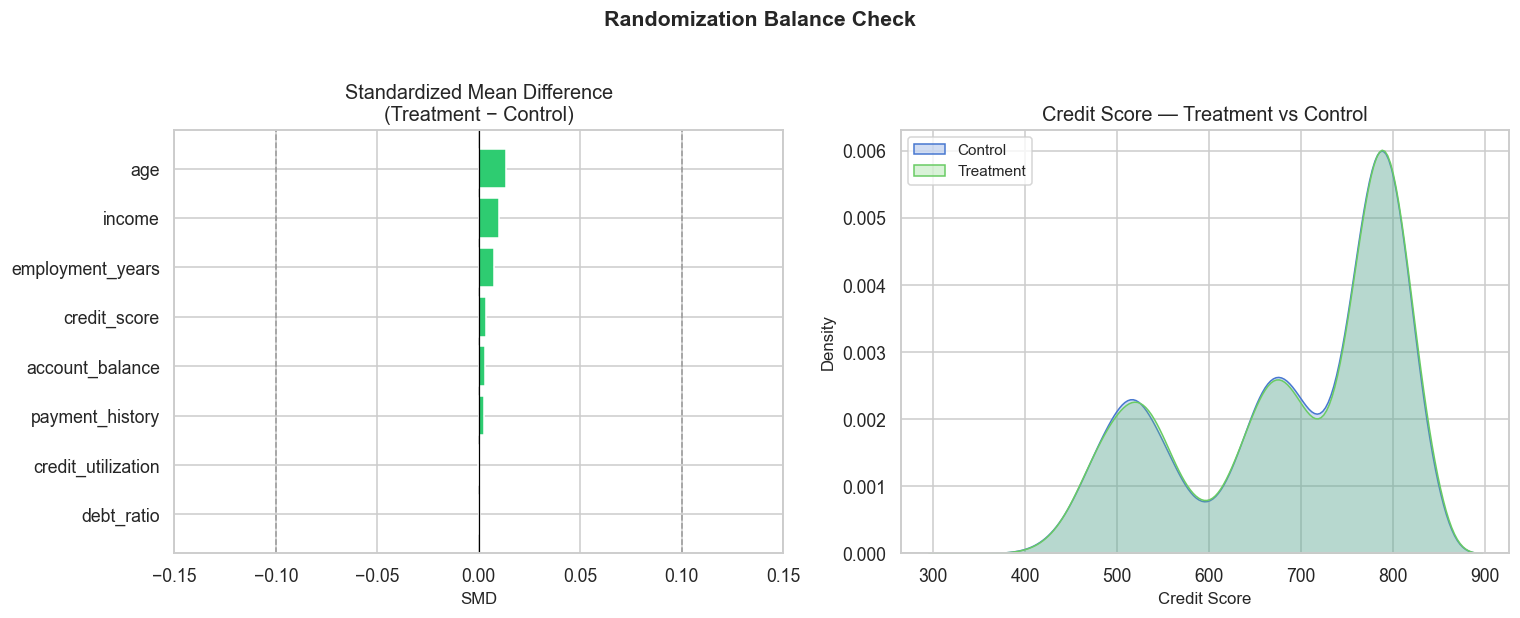

Treatment rate: 49.90%
Max |SMD|: 0.0136  (threshold: 0.10)


,feature,smd
4,debt_ratio,0.000437
7,credit_utilization,-0.000528
6,payment_history,0.002423
3,account_balance,0.002979
5,credit_score,0.003546
2,employment_years,0.007665
1,income,0.010024
0,age,0.013647


In [6]:
balance_features = [
    "age", "income", "employment_years", "account_balance",
    "debt_ratio", "credit_score", "payment_history", "credit_utilization",
]

def standardized_mean_difference(treated, control):
    """Cohen's d-style SMD for balance diagnostics."""
    diff = treated.mean() - control.mean()
    pooled_std = np.sqrt((treated.var() + control.var()) / 2)
    return diff / pooled_std if pooled_std > 0 else 0.0

treated = df[df["marketing_offer"] == 1]
control = df[df["marketing_offer"] == 0]

smd_rows = []
for col in balance_features:
    smd = standardized_mean_difference(treated[col], control[col])
    smd_rows.append({"feature": col, "smd": smd})
smd_df = pd.DataFrame(smd_rows).sort_values("smd", key=abs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# SMD plot (|SMD| < 0.1 indicates good balance)
colors = ["#2ecc71" if abs(v) < 0.1 else "#e67e22" for v in smd_df["smd"]]
axes[0].barh(smd_df["feature"], smd_df["smd"], color=colors, edgecolor="white")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].axvline(-0.1, color="gray", ls="--", lw=1, alpha=0.7)
axes[0].axvline(0.1, color="gray", ls="--", lw=1, alpha=0.7)
axes[0].set_title("Standardized Mean Difference\n(Treatment − Control)")
axes[0].set_xlabel("SMD")
axes[0].set_xlim(-0.15, 0.15)

# Example covariate overlay: credit score
for group_name, subset, color in [("Control", control, TREATMENT_PALETTE["Control"]),
                                   ("Treatment", treated, TREATMENT_PALETTE["Treatment"])]:
    sns.kdeplot(subset["credit_score"], label=group_name, color=color, fill=True, alpha=0.25, ax=axes[1])
axes[1].set_title("Credit Score — Treatment vs Control")
axes[1].set_xlabel("Credit Score")
axes[1].legend()

plt.suptitle("Randomization Balance Check", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_treatment_balance.png", bbox_inches="tight", dpi=150)
plt.show()

print(f"Treatment rate: {df['marketing_offer'].mean():.2%}")
print(f"Max |SMD|: {smd_df['smd'].abs().max():.4f}  (threshold: 0.10)")
smd_df

## 5. Response Rate Comparison

Compare loan application rates overall and between treatment and control. The **observed difference** is the naive average treatment effect — informative, but confounded if randomization failed.

C:\Users\GWX\AppData\Local\Temp\ipykernel_55556\847657466.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


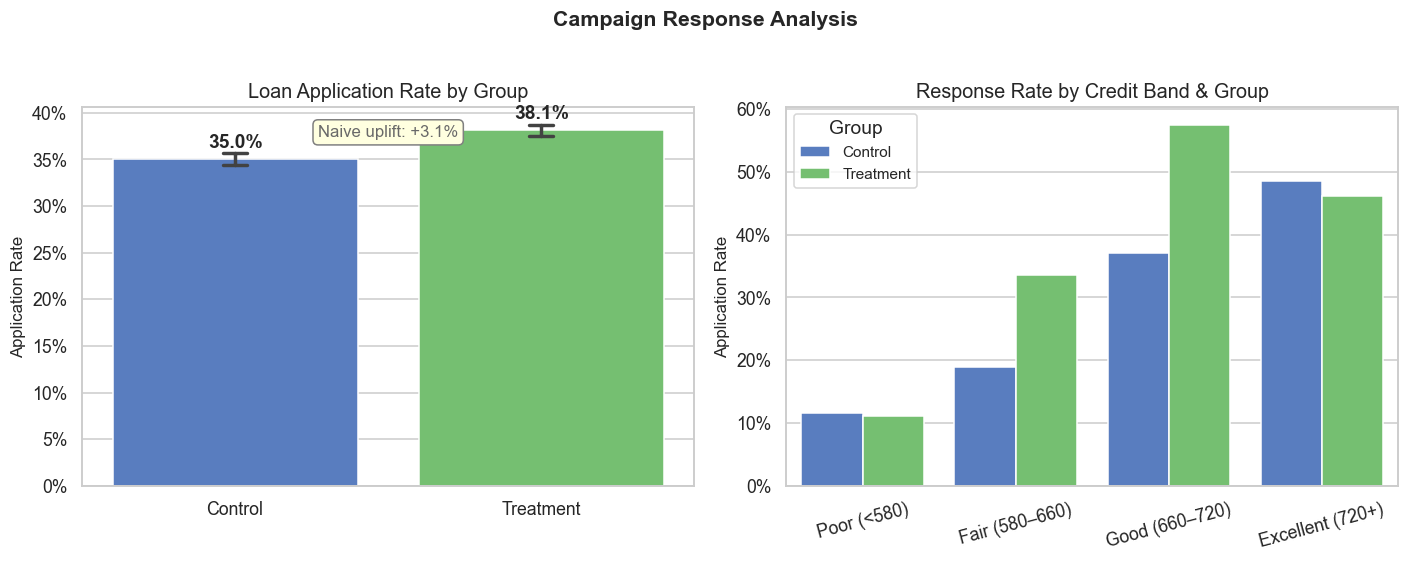

Overall response rate: 36.58%


,customers,applications,response_rate
group,,,
Control,25048,8770,0.350128
Treatment,24952,9518,0.381452


In [7]:
response_overall = df["loan_application"].mean()
response_by_group = df.groupby("group")["loan_application"].agg(["count", "sum", "mean"])
response_by_group.columns = ["customers", "applications", "response_rate"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart: response rate by group
sns.barplot(
    data=df, x="group", y="loan_application", order=["Control", "Treatment"],
    palette=TREATMENT_PALETTE, errorbar=("ci", 95), capsize=0.08, ax=axes[0],
)
axes[0].set_title("Loan Application Rate by Group")
axes[0].set_xlabel("")
axes[0].set_ylabel("Application Rate")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
for i, (idx, row) in enumerate(response_by_group.iterrows()):
    axes[0].text(i, row["response_rate"] + 0.012, f"{row['response_rate']:.1%}", ha="center", fontweight="bold")

naive_uplift = (
    response_by_group.loc["Treatment", "response_rate"]
    - response_by_group.loc["Control", "response_rate"]
)
axes[0].annotate(
    f"Naive uplift: {naive_uplift:+.1%}", xy=(0.5, 0.92), xycoords="axes fraction",
    ha="center", fontsize=11, color="dimgray",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="gray"),
)

# Response rate by credit score band
df["credit_band"] = pd.cut(
    df["credit_score"], bins=[300, 580, 660, 720, 850],
    labels=["Poor (<580)", "Fair (580–660)", "Good (660–720)", "Excellent (720+)"],
)
band_response = df.groupby(["credit_band", "group"], observed=False)["loan_application"].mean().reset_index()
sns.barplot(
    data=band_response, x="credit_band", y="loan_application", hue="group",
    hue_order=["Control", "Treatment"], palette=TREATMENT_PALETTE, ax=axes[1],
)
axes[1].set_title("Response Rate by Credit Band & Group")
axes[1].set_xlabel("")
axes[1].set_ylabel("Application Rate")
axes[1].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Group")

plt.suptitle("Campaign Response Analysis", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_response_rates.png", bbox_inches="tight", dpi=150)
plt.show()

print(f"Overall response rate: {response_overall:.2%}")
response_by_group

## 6. Customer Segment Analysis

Uplift modeling targets **heterogeneous treatment effects** — customers who respond differently to marketing. Segments reveal where the campaign helps, is neutral, or may hurt.

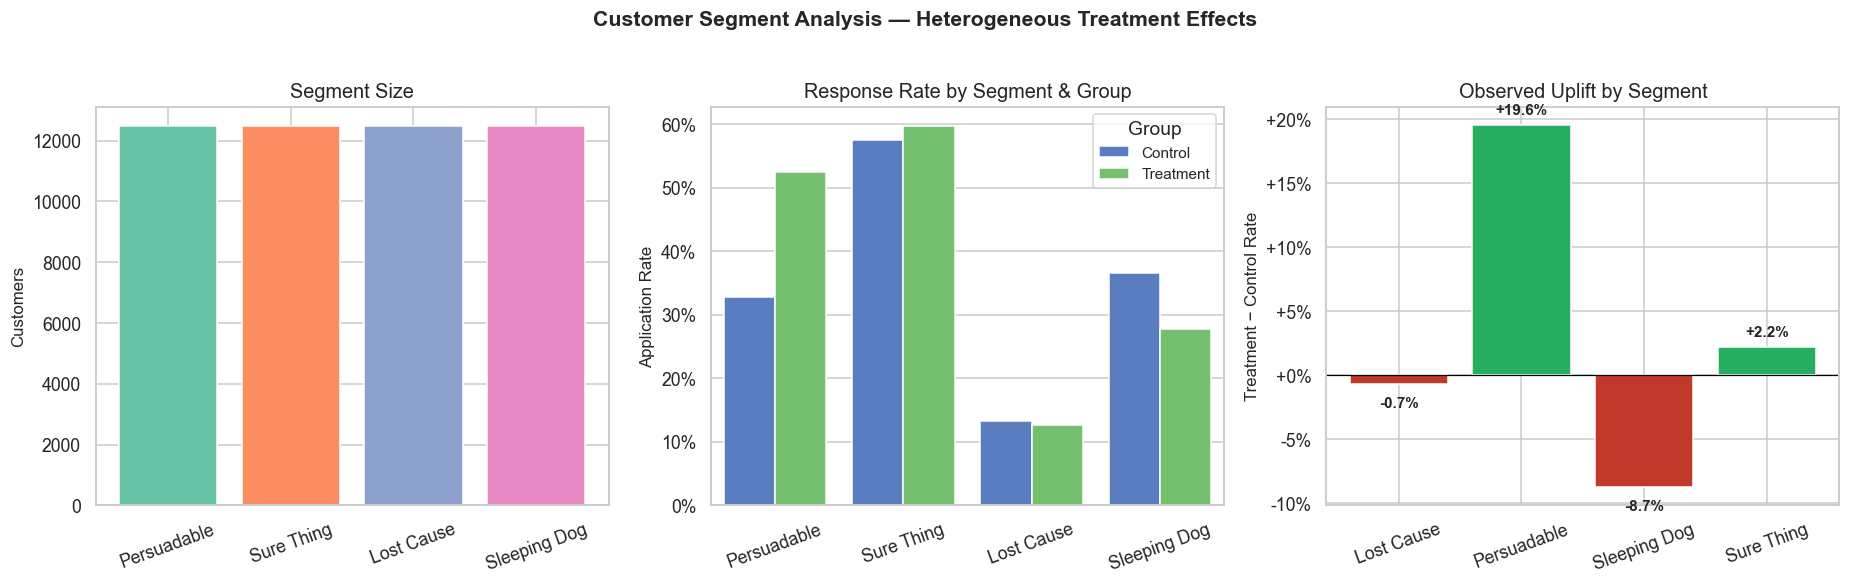

,overall_rate,control_rate,treatment_rate,uplift
Lost Cause,0.129,0.133,0.126,-0.007
Persuadable,0.425,0.328,0.524,0.196
Sleeping Dog,0.322,0.365,0.278,-0.087
Sure Thing,0.587,0.576,0.598,0.022


In [8]:
segment_sizes = df["customer_segment"].value_counts().reindex(SEGMENT_ORDER)

segment_response = (
    df.groupby(["customer_segment", "group"])["loan_application"]
    .mean()
    .reset_index()
)
segment_response["segment_label"] = segment_response["customer_segment"].map(SEGMENT_LABELS)

uplift_table = (
    df.groupby("customer_segment")["loan_application"]
    .agg(overall_rate="mean")
    .join(
        df.groupby(["customer_segment", "marketing_offer"])["loan_application"].mean()
        .unstack()
        .rename(columns={0: "control_rate", 1: "treatment_rate"})
    )
)
uplift_table["uplift"] = uplift_table["treatment_rate"] - uplift_table["control_rate"]
uplift_table.index = [SEGMENT_LABELS[s] for s in uplift_table.index]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# Segment size
axes[0].bar(
    [SEGMENT_LABELS[s] for s in SEGMENT_ORDER],
    segment_sizes.values,
    color=[SEGMENT_COLORS[s] for s in SEGMENT_ORDER],
    edgecolor="white",
)
axes[0].set_title("Segment Size")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=20)

# Response rate by segment and group
sns.barplot(
    data=segment_response, x="segment_label", y="loan_application", hue="group",
    hue_order=["Control", "Treatment"], palette=TREATMENT_PALETTE,
    order=[SEGMENT_LABELS[s] for s in SEGMENT_ORDER], ax=axes[1],
)
axes[1].set_title("Response Rate by Segment & Group")
axes[1].set_xlabel("")
axes[1].set_ylabel("Application Rate")
axes[1].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="Group")

# Uplift by segment
uplift_values = uplift_table["uplift"].values
bar_colors = ["#27ae60" if u > 0 else "#c0392b" for u in uplift_values]
axes[2].bar(uplift_table.index, uplift_values, color=bar_colors, edgecolor="white")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Observed Uplift by Segment")
axes[2].set_ylabel("Treatment − Control Rate")
axes[2].yaxis.set_major_formatter(lambda x, _: f"{x:+.0%}")
axes[2].tick_params(axis="x", rotation=20)
for i, v in enumerate(uplift_values):
    axes[2].text(i, v + (0.008 if v >= 0 else -0.018), f"{v:+.1%}", ha="center", fontweight="bold", fontsize=10)

plt.suptitle("Customer Segment Analysis — Heterogeneous Treatment Effects", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_segment_analysis.png", bbox_inches="tight", dpi=150)
plt.show()

uplift_table.round(3)

## Correlation Does Not Imply Causation

Exploratory analysis reveals **associations** — variables that tend to move together. It does **not** prove that one variable *causes* another.

| Concept | Meaning in this campaign |
|---------|--------------------------|
| **Correlation** | High credit score is *associated with* higher application rates |
| **Causation** | Sending a marketing offer *causes* a change in application probability |

### Why the distinction matters

1. **Confounding** — Wealthier customers may both have higher credit scores *and* apply more often. Credit score correlates with response but may not be the driver.
2. **Reverse causality** — Frequent app usage correlates with applications, but applications may also increase app usage.
3. **Selection bias** — If treatment were not randomized, treated customers might differ systematically, making observed differences uninterpretable.

### What we can trust here

- **Randomized treatment** (`marketing_offer`) supports a *causal* comparison of treatment vs control at the population level (ATE).
- **Correlations among observables** (e.g., income ↔ credit score) describe customer structure, not marketing impact.
- **Segment-level uplift** in this synthetic dataset reflects known data-generating effects; in production, uplift models must estimate these from experimental data — not from correlation alone.

> **Bottom line:** Use EDA to understand data quality and patterns. Use randomized experiments and causal inference / uplift modeling to estimate the *effect* of marketing.

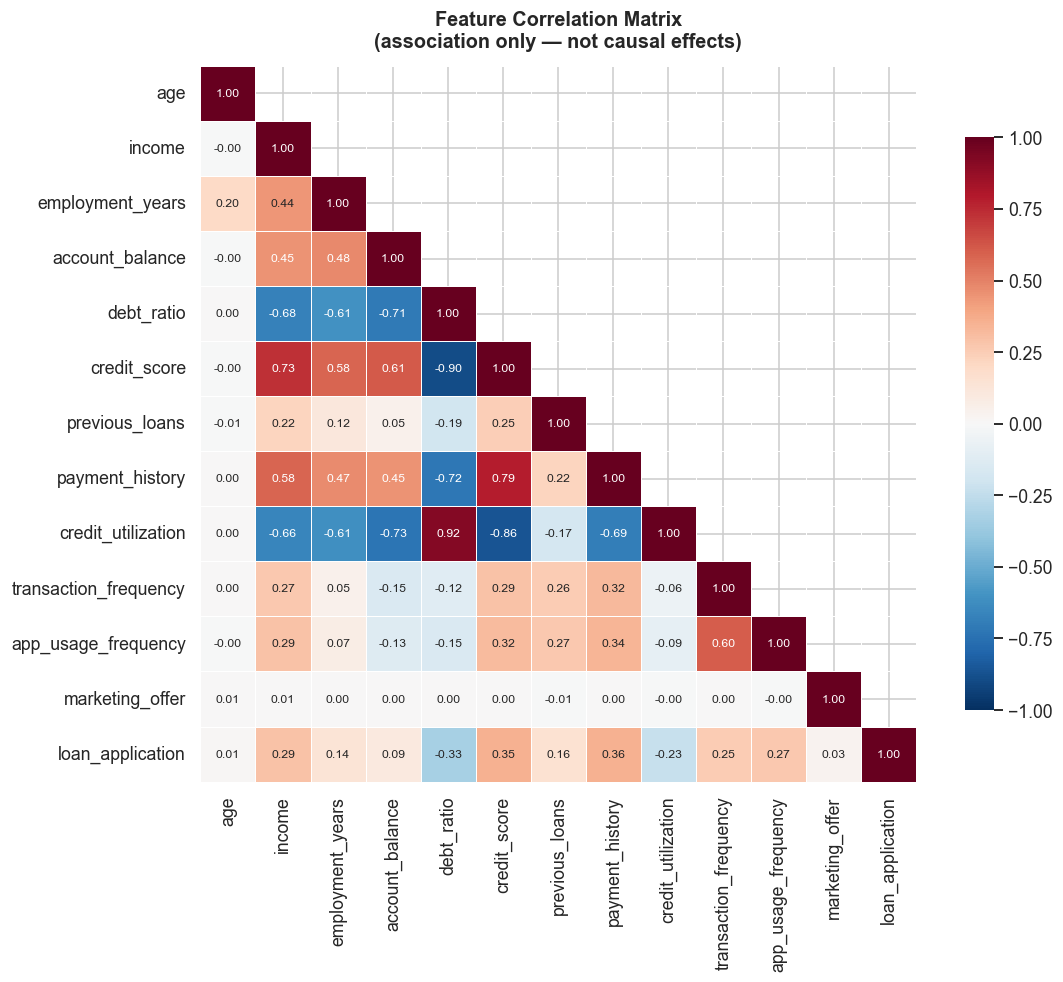

Correlation(credit_score, loan_application)     = +0.354  ← observational association
Correlation(marketing_offer, loan_application)  = +0.033  ← weak globally; effect varies by segment


In [9]:
numeric_cols = [
    "age", "income", "employment_years", "account_balance", "debt_ratio",
    "credit_score", "previous_loans", "payment_history", "credit_utilization",
    "transaction_frequency", "app_usage_frequency", "marketing_offer", "loan_application",
]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 8}, square=True,
    linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title(
    "Feature Correlation Matrix\n(association only — not causal effects)",
    fontsize=13, fontweight="bold", pad=12,
)
plt.tight_layout()
plt.savefig(REPORT_DIR / "eda_correlation_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

# Highlight: credit score vs loan application is correlational
r_score_response = df["credit_score"].corr(df["loan_application"])
r_treatment_response = df["marketing_offer"].corr(df["loan_application"])
print(f"Correlation(credit_score, loan_application)     = {r_score_response:+.3f}  ← observational association")
print(f"Correlation(marketing_offer, loan_application)  = {r_treatment_response:+.3f}  ← weak globally; effect varies by segment")

---

### Key Takeaways

1. The population spans diverse demographics with realistic financial and credit profiles.
2. Treatment and control groups are well balanced (low SMDs), supporting causal A/B analysis.
3. Overall naive uplift is positive, but **segment-level effects differ sharply** — the core motivation for uplift modeling.
4. Correlations among features help feature engineering but must not be interpreted as marketing causal effects.

**Next steps:** Feature preprocessing → propensity/overlap checks → uplift model training → Qini/AUUC evaluation.